# 2장 · 파이썬 핵심 문법과 중첩 데이터 읽기

학습 기록 세 건 중에서 30분 이상 공부하고 완료라고 표시한 제목만 뽑으려고 합니다. 한 건을 읽어 조건을 결정한 다음 세 건 전체에 같은 규칙을 적용합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 한 건의 칸을 이름으로 찾기

리스트에서는 순서로, 딕셔너리에서는 키로 값을 찾습니다. 자료의 바깥쪽에서 안쪽으로 한 단계씩 내려가 보세요.


### 셀 01 · 첫 번째 기록 꺼내기

records에는 제목이 있는 기록 세 건이 차례로 들어 있습니다.

data["records"]는 기록 전체입니다. 여기에 [0]을 붙이면 첫 번째 기록 한 건이 남고, 그 기록에서 ["minutes"]를 읽으면 숫자 30이 나옵니다. 두 번째 기록을 읽으려면 어느 대괄호의 숫자를 바꿔야 할까요?

In [1]:
data = {"records": [
    {"title": "  Python 기초 ", "minutes": 30, "done": True},
    {"title": "Git 연습", "minutes": 20, "done": False},
    {"title": " 리스트 복습 ", "minutes": 40, "done": True},
]}
first = data["records"][0]
print(first["minutes"])

30


30은 첫 기록의 시간입니다. [0]은 첫 번째 기록을, ["minutes"]는 그 기록의 시간을 골랐습니다.

### 셀 02 · 제목 양끝의 공백 지우기

원본의 제목을 화면에 표시하기 전 바깥 공백만 잘라 냅니다.

In [2]:
print(first["title"].strip())

Python 기초


Python 기초가 나옵니다. strip은 정리한 문자열을 돌려줍니다. first 안의 title을 새 값으로 바꾸지는 않습니다.

### 과제 03 · 둘째 기록의 완료 여부

data만 사용해 두 번째 기록의 done 값을 꺼내 출력하세요.

In [3]:
# 두 번째 기록에서 done을 읽으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(data[&quot;records&quot;][1][&quot;done&quot;])</code></pre>
<p>실행 결과</p><pre><code>False</code></pre>
<p>False는 둘째 기록이 미완료라는 뜻입니다. 기록을 고르는 [1]과 항목을 고르는 [&quot;done&quot;]의 순서를 바꾸면 리스트에서 문자열 키를 찾으려다 오류가 납니다.</p>
</details>

## 조건을 만족한 제목 모으기

두 조건이 동시에 맞아야 합니다. 한 건에서 True 또는 False를 얻은 뒤, 그 조건이 참인 기록의 제목만 새 리스트에 담아 봅시다.

<!-- motion:minute-sieve -->
**어떤 기록이 70분에 들어갈까요?**

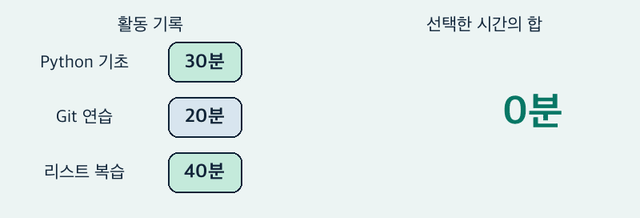

완료했고 30분 이상인 두 기록만 합계에 들어갑니다. Git 연습은 미완료이고 20분이어서 합계에서 빠집니다.
<!-- /motion -->


### 셀 04 · 30분도 포함할까요?

첫 기록은 정확히 30분입니다. 경계에 걸친 이 기록이 선택되는지 보세요.

In [4]:
print(first["done"] and first["minutes"] >= 30)

True


True가 나옵니다. >=의 등호 때문에 정확히 30분인 기록도 포함됩니다.

### 셀 05 · 조건을 통과한 제목 모으기

for의 record는 반복할 때마다 다른 한 건을 가리킵니다.

In [5]:
selected = []
for record in data["records"]:
    if record["done"] and record["minutes"] >= 30:
        selected.append(record["title"].strip())
print(selected)

['Python 기초', '리스트 복습']


Python 기초와 리스트 복습만 남습니다. Git 연습은 완료 표시가 없고 20분이어서 append까지 가지 않습니다.

### 과제 06 · 선택한 기록의 총시간

같은 조건을 통과한 시간만 total에 누적하고 마지막에 출력하세요.

In [6]:
total = 0
# 여기에 반복문을 작성하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>total = 0
for record in data[&quot;records&quot;]:
    if record[&quot;done&quot;] and record[&quot;minutes&quot;] &gt;= 30:
        total += record[&quot;minutes&quot;]
print(total)</code></pre>
<p>실행 결과</p><pre><code>70</code></pre>
<p>30에 40을 더해 70이 됩니다. total = 0을 반복문 안에 넣으면 이전 기록에서 모은 시간이 사라집니다.</p>
</details>

## 문자로 받은 기록 읽기

다른 프로그램이 보낸 JSON은 파이썬 사전처럼 보이지만 처음에는 문자열입니다. 자료를 해석한 다음에 키를 꺼냅니다.


### 셀 07 · JSON의 true 읽기

작은따옴표 안의 전체 내용이 받은 문자열입니다.

In [7]:
import json
raw = '{"title":"Python","done":true,"memo":null}'
record = json.loads(raw)
print(record["memo"])

None


JSON의 null이 파이썬 값 None으로 바뀌었습니다. 같은 방식으로 true는 True가 됩니다. raw에서 바로 ["memo"]를 꺼낼 수 없는 이유는 변환 전에는 글자만 있기 때문입니다.

## 돌아보기

시간 기준을 40분으로 바꾸면 어떤 제목이 남을까요? 예상한 뒤 조건 셀부터 다시 실행하세요. 원문이 문자열인지, records가 리스트인지, record가 한 건인지 차례로 짚으면 인덱스와 키를 혼동한 위치도 찾을 수 있습니다.

### 필터와 누적값 추적

**빈 결과 준비**　반복 전에 한 번만 초기화합니다.

```
selected = []
total = 0
```

**Python 기초 포함**　done이 True이고 30 >= 30입니다.

```
selected = ['Python 기초']
total = 30
```

**Git 연습 제외**　done이 False여서 결과를 바꾸지 않습니다.

```
selected = ['Python 기초']
total = 30
```

**리스트 복습 포함**　40분을 기존 합계에 더합니다.

```
selected = ['Python 기초', '리스트 복습']
total = 70
```
